# HIV Treatment Using Optimal Control

**Seong Cho** · ACME Volume 4, Lab 23

**Lab objective:** use optimal control to find the optimal dosage of a two-drug combination for HIV treatment, by iteratively solving the state and costate equations with RK4.

<sub>Lab specification from the *Volume 4* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

## Introduction

Viruses (ebola, influenza, the common cold, HIV) are not considered living organisms since they cannot reproduce on their own: they inject their genes as DNA or RNA into a host's genome, use the cell's ribosomes and proteins to replicate, then lyse the cell and release many virus particles to infect other cells.

The adaptive immune system relies on T cells, in particular the helper T cell, or CD4+T cell, which regulates the immune response. HIV specifically targets this type of T cell, and the loss of CD4+T cells is what causes Acquired Immune Deficiency Syndrome (AIDS). AIDS itself is not an infection: without T cells to recognize viruses and bacteria, the body becomes susceptible to other infections. Since it may be several years before the host notices the effects, HIV spreads more easily.

There is no cure or vaccine for HIV, but treatments reduce the virus and bolster the immune system by increasing the CD4+T cell count. These treatments can be expensive and have negative side effects, so it is important to optimize the amount of drugs used; this lab finds the optimal dosage of a two-drug combination (Lenhart, *Short Courses on the Mathematics of Biological Complexity*).

## Derivation of Control

Let $T$ be the concentration of CD4+T cells and $V$ the concentration of HIV particles. $s_1$ and $s_2$ represent the production of T cells by various processes, $B_1$ and $B_2$ are half saturation constants, $\mu$ is the death rate of uninfected T cells, $k$ the rate of infection of T cells, $c$ the death rate of the virus, and $g$ the input rate of an external viral source. The controls $u_1$ and $u_2$ are the amounts of drugs that introduce new T cells or kill the virus, respectively (Kirschner and Webb, 1998). The state system is

$$\begin{aligned}
\frac{dT}{dt} &= s_1 - \frac{s_2V(t)}{B_1 + V(t)} - \mu T(t) - kV(t)T(t) + u_1(t)T(t), \\
\frac{dV}{dt} &= \frac{gV(t)}{B_2 + V(t)}(1 - u_2(t)) - cV(t)T(t),
\end{aligned} \tag{23.1}$$

with $T(0) = T_0$, $V(0) = V_0$. Here $s_1 - \frac{s_2V}{B_1 + V}$ is the source/proliferation of unaffected T cells, $\mu T$ their natural loss, $kVT$ the loss of T cells by infection, $\frac{gV}{B_2 + V}$ the viral contribution to plasma and $cVT$ the viral loss (Joshi, *Optimal Control of an HIV Immunology Model*).

We seek to maximize

$$J(u_1, u_2) = \int_0^{t_f}\left[T - (A_1u_1^2 + A_2u_2^2)\right]dt,$$

which weighs the benefit of T cells against the systematic costs of the drugs ($A_1$, $A_2$ scale the cost terms), over $U = \{(u_1, u_2) \mid u_i \text{ measurable},\ a_i \le u_i \le b_i,\ t \in [0, t_f]\}$.

## Optimality System

With costate $\lambda$, the Hamiltonian is

$$H = \lambda_1\left[s_1 - \frac{s_2V}{B_1 + V} - \mu T - kVT + u_1T\right] + \lambda_2\left[\frac{g(1 - u_2)V}{B_2 + V} - cVT\right] + \left[T - (A_1u_1^2 + A_2u_2^2)\right],$$

and the costate equations are

$$\begin{aligned}
\lambda_1' &= -\frac{\partial H}{\partial T} = -1 + \lambda_1[\mu + kV^* - u_1^*] + \lambda_2cV^*, \\
\lambda_2' &= -\frac{\partial H}{\partial V} = \lambda_1\left[\frac{B_1s_2}{(B_1 + V^*)^2} + kT^*\right] - \lambda_2\left[\frac{B_2g(1 - u_2^*)}{(B_2 + V^*)^2} - cT^*\right],
\end{aligned}$$

with transversality (endpoint) conditions $\lambda_1(t_f) = \lambda_2(t_f) = 0$. Setting $\partial H/\partial u_i = 0$ gives $u_1^* = \frac{1}{2A_1}\lambda_1T^*$ and $u_2^* = -\frac{1}{2A_2}\lambda_2\frac{gV^*}{B_2 + V^*}$, and with the bounds on the controls,

$$u_1^*(t) = \min\left\{\max\left\{a_1, \frac{1}{2A_1}\lambda_1T^*(t)\right\}, b_1\right\}, \qquad u_2^*(t) = \min\left\{\max\left\{a_2, -\frac{\lambda_2}{2A_2}\frac{gV^*(t)}{B_2 + V^*(t)}\right\}, b_2\right\}.$$

Substituting these into the state and costate equations gives the optimality system (23.2)–(23.3), with $\lambda_1(t_f) = \lambda_2(t_f) = 0$, $T(0) = T_0$, $V(0) = V_0$.

## Creating a Numerical Solver

Solve for $u$ iteratively: each iteration solves the state equations and the costate equations numerically, uses them to find a new control, and checks whether the control has converged. The RK4 solver from the earlier lab gets one adjustment: the state equations depend on $u$ and the costate equations on the state, so the function passed to RK4 also takes an index into those arrays.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

#Code from RK4 Lab with minor edits
def initialize_all(y0, t0, t, n):
    """ An initialization routine for the different ODE solving
    methods in the lab. This initializes Y, T, and h. """
    if isinstance(y0, np.ndarray):
        Y = np.empty((n, y0.size)).squeeze()
    else:
        Y = np.empty(n)
    Y[0] = y0
    T = np.linspace(t0, t, n)
    h = float(t - t0) / (n - 1)
    return Y, T, h

def RK4(f, y0, t0, t, n):
    """ Use the RK4 method to compute an approximate solution
    to the ODE y' = f(t, y) at n equispaced parameter values from t0 to t
    with initial conditions y(t0) = y0.
    y0 is assumed to be either a constant or a one-dimensional numpy array.
    t and t0 are assumed to be constants.
    f is assumed to accept three arguments.
    The first is a constant giving the value of t.
    The second is a one-dimensional numpy array of the same size as y.
    The third is an index to the other arrays.
    This function returns an array Y of shape (n,) if
    y is a constant or an array of size 1.
    It returns an array of shape (n, y.size) otherwise.
    In either case, Y[i] is the approximate value of y at
    the i'th value of np.linspace(t0, t, n).
    """
    Y,T,h = initialize_all(y0,t0,t,n)
    for i in range(n-1):
        K1 = f(T[i],Y[i],i)
        K2 = f(T[i]+h/2.,Y[i]+h/2.*K1,i)
        K3 = f(T[i]+h/2.,Y[i]+h/2.*K2,i)
        K4 = f(T[i+1],Y[i]+h*K3,i)
        Y[i+1] = Y[i] + h/6.*(K1+2*K2 +2*K3+K4)
    return Y

> **Achtung!** When solving the state equations, because of the nature of $T'$ and $V'$, solve the original equations (23.1) from the beginning of the lab and not the equations (23.2) with $u_i^*(t)$ replaced by the minmax function.

## Problem 1: The state equations

> **Problem 1.** Create a function that defines the state equations and returns both equations in a single array. The function should be able to be passed into the RK4 solver. This function can depend on the global variables defined below.

In [2]:
# global variables
a_1, a_2 = 0, 0
b_1, b_2 = 0.02, 0.9
s_1, s_2 = 2., 1.5
mu = 0.002
k = 0.000025
g = 30.
c = 0.007
B_1, B_2 = 14, 1
A_1, A_2 = 250000, 75
T0, V0 = 400, 3
t_f = 50
n = 1000

#State, costate, control arrays (with inital control guess)
state = np.zeros((n,2))
state0 = np.array([T0, V0])

costate = np.zeros((n,2))
costate0 = np.zeros(2)

u=np.zeros((n,2))
u[:,0] += .02
u[:,1] += .9

# define state equations
def state_equations(t,y,i):
    '''
    Parameters
    ---------------
    t : float the time
    y : ndarray (2,) the T cell concentration and the Virus concentration at time t
    i : int index for the global variable u.
    Returns
    --------------
    y_dot : ndarray (2,)
    the derivative of the T cell concentration and the virus concentration at time t
    '''
    DT = s_1 - s_2*y[1] / (B_1 + y[1]) - mu*y[0] - k*y[0]*y[1] + u[i,0]*y[0]
    DV = (g*y[1] / (B_2 + y[1]))*(1 - u[i,1]) - c*y[0]*y[1]
    return np.array([DT, DV])

The costate equations have end conditions rather than initial conditions, so RK4 should iterate backwards from the end. Define $\hat{\lambda}_i(t) = \lambda_i(t_f - t)$, with initial conditions $\hat{\lambda}_i(0) = \lambda_i(t_f)$:

$$\begin{aligned}
\dot{\hat{\lambda}}_1(t) &= \lambda_1(t_f - t)\left(-\mu - kV(t_f - t) + u_1(t_f - t)\right) - c\lambda_2(t_f - t)V(t_f - t) + 1, \\
\dot{\hat{\lambda}}_2(t) &= -\lambda_1(t_f - t)\left(\frac{s_2B_1}{(B_1 + V(t_f - t))^2} + kT(t_f - t)\right) + \lambda_2(t_f - t)\left(\frac{gB_2(1 - u_2(t_f - t))}{(B_2 + V(t_f - t))^2} - cT(t_f - t)\right).
\end{aligned}$$

Solve these with RK4 and recover the original costate by indexing the array backwards.

## Problem 2: The costate equations

> **Problem 2.** Create a function that defines the costate equations and returns both equations in a single array. The function should be able to be passed into the RK4 solver. Use the global variables as defined in Problem 1.

In [3]:
def lambda_hat(t,y,i):
    '''
    Parameters
    ---------------
    t : float
        the time
    y : ndarray (2,)
        the lambda_hat values at time t
    i : int
        index for global variables, u and state.
    Returns
    --------------
    y_dot : ndarray (2,)
        the derivative of the lambda_hats at time t.
    '''
    T = state[-i-1,0]
    V = state[-i-1,1]
    u1 = u[-i-1,0]
    u2 = u[-i-1,1]
    Dlambda_1 = y[0]*(-mu - k*V + u1) - c*y[1]*V - 1
    Dlambda_2 = -y[0]*(s_2*B_1 / (B_1 + V)**2 + k*T) + \
                y[1]*(g*B_2*(1 - u2) / (B_2 + V)**2 - c*T)
    return np.array([Dlambda_1, Dlambda_2])

## Problem 3: The solver

> **Problem 3.** Create and run a numerical solver for the HIV two drug model using the code below.

In [4]:
epsilon = 0.001
test = epsilon + 1
while(test > epsilon):
    oldu = u.copy();
    
    #solve the state equations with forward iteration
    state = RK4(state_equations, state0, 0, t_f, n)
    
    #solve the costate equations with backwards iteration
    costate = RK4(lambda_hat, costate0, 0, t_f, n)[::-1]
    
    #solve for u1 and u2
    opt_u1 = (-1/(2*A_1))*costate[:,0]*state[:,0]
    opt_u2 = (1/(2*A_2))*costate[:,1]*g*state[:,1] / (B_2 + state[:,1])
    u1_1 = np.dstack([a_1*np.ones(n), opt_u1])[0].max(axis=1)
    u2_1 = np.dstack([a_2*np.ones(n), opt_u2])[0].max(axis=1)
    u1 = np.dstack([b_1*np.ones(n), u1_1])[0].min(axis=1)
    u2 = np.dstack([b_2*np.ones(n), u2_1])[0].min(axis=1)
    
    #update control
    u[:,0] = 0.5*(u1 + oldu[:,0])
    u[:,1] = 0.5*(u2 + oldu[:,1])
    
    #test for convergence
    test = abs(oldu - u).sum()

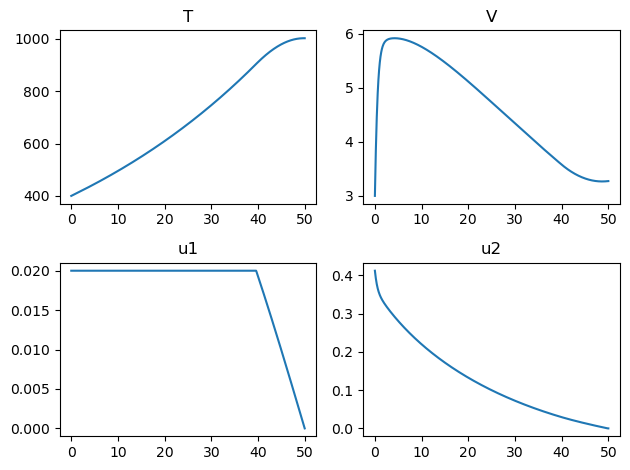

In [5]:
T = state[:, 0]
V = state[:, 1]
u1 = u[:, 0]
u2 = u[:, 1]
time_domain = np.linspace(0, t_f, n)
plt.subplot(221)
plt.plot(time_domain, T)
plt.title("T")
plt.subplot(222)
plt.plot(time_domain, V)
plt.title("V")
plt.subplot(223)
plt.plot(time_domain, u1)
plt.title("u1")
plt.subplot(224)
plt.plot(time_domain, u2)
plt.title("u2")
plt.tight_layout()
plt.show()

In modern medicine, patients generally take combinations of five or more medications with different functions: Nucleotide Reverse Transcriptase Inhibitors, which prevent HIV inserting its genes into host DNA; Non-Nucleoside Reverse Transcriptase Inhibitors, which do the same job in a different fashion; Protease Inhibitors, which cut up replicated HIV strands; Fusion Inhibitors, which block the virus from entering the cells to begin with; and Integrase Inhibitors, which prevent the virus' replicated DNA from being inserted into a cell's DNA. These drugs can interact with each other and have different side effects, and doctors rotate medications as the body and virus develop immunity.